# VulHunter - Binary Vulnerability Detection (Fusion Mode - FiLM Enhanced v2)

Notebook này huấn luyện **VulHunterModel** ở chế độ **Fusion** tích hợp **4 Giải pháp Cải tiến Đột phá**:
- 🥇 **Giải pháp 1 (Enriched Node Features)**: Làm giàu đặc trưng Node của R-GCN bằng nội dung mã nguồn (`node_texts`) qua bảng băm subtoken 16,384 chiều kết hợp AST types.
- 🥈 **Giải pháp 2 (Shared Backbone Option)**: Chia sẻ trực tiếp Word Embeddings 50,265 tokens của CodeBERT cho các node trong graph, xóa bỏ domain gap giữa hai nhánh.
- 🚀 **Hybrid Mode (1 + 2 Đồng Thời)**: Kết hợp song song cả Giải pháp 1 (học từ vựng lỗ hổng chuyên biệt) và Giải pháp 2 (tri thức ngôn ngữ tổng quát từ CodeBERT).
- 🥉 **Giải pháp 3 (FiLM Modulation & Additive Residual Skip)**: Điều biến biểu diễn Semantic bằng Graph context thông qua FiLM (`(1 + gamma) * semantic + beta`), hỗ trợ cả Token-level và Pooled Late Fusion + Additive Residual Skip bảo vệ tín hiệu pre-trained.
- 🛡️ **Giải pháp 4 (Vulnerability-Aware Node Features)**: Nhúng trực tiếp các cờ nhận diện lỗ hổng (`is_source`, `is_sink`, `is_sanitizer`) vào từng node của PDG đồ thị, tập trung message passing vào đường dẫn lan truyền dữ liệu nguy hiểm (taint flow).

**Môi trường: Kaggle 2xT4 (16GB), Internet ON, FP16 mixed precision.**


## 1. Setup môi trường


In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "true"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"


import json
import math
import time
import random
from pathlib import Path
from tqdm.auto import tqdm
import gc
import shutil
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from functools import partial

# ⚡ Kỹ thuật tối ưu: CuDNN benchmark mode
torch.backends.cudnn.benchmark = True

try:
    from transformers import set_seed
    set_seed(42)
except ImportError:
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
from torch.utils.data import DataLoader

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)

sns.set_theme(style="whitegrid", context="notebook")

IS_KAGGLE = Path('/kaggle').exists()
print(f'IS_KAGGLE = {IS_KAGGLE}')
print(f'PyTorch   = {torch.__version__}')
if torch.cuda.is_available():
    print(f'GPUs      = {torch.cuda.device_count()}')
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f'  GPU {i}: {p.name} - {p.total_memory/1e9:.1f} GB')

IS_KAGGLE = True
PyTorch   = 2.11.0+cu128
GPUs      = 2
  GPU 0: Tesla T4 - 15.6 GB
  GPU 1: Tesla T4 - 15.6 GB


In [2]:
import subprocess
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
import json
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)
sns.set_theme(style='whitegrid', context='notebook')

# Clone hoac cap nhat VulHunter repo tu GitHub
GITHUB_REPO = 'https://github.com/NhatWoan-20/VulHunter.git'
REPO_DIR = Path('/kaggle/working/VulHunter') if IS_KAGGLE else Path.cwd()
if not REPO_DIR.exists():
    print(f'Cloning VulHunter from GitHub to {REPO_DIR}...')
    result = subprocess.run(['git', 'clone', GITHUB_REPO, str(REPO_DIR)],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f'Clone failed: {result.stderr}')
        raise RuntimeError('Failed to clone VulHunter repo')
    print('Clone successful!')
    print('Installing dependencies...')
    subprocess.run(['pip', 'install', '-e', str(REPO_DIR), '-q'],
                   capture_output=True)
else:
    print(f'VulHunter repo da ton tai tai {REPO_DIR}, pulling commit moi nhat...')
    subprocess.run(['git', '-C', str(REPO_DIR), 'pull'], capture_output=True)

import sys
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f'Using repo: {REPO_DIR}')

# Test imports
import importlib
print('Testing imports...')
errors = []
modules_to_test = [
    'src.multitask.model',
    'src.utils.dataset',
    'src.utils.losses',
    'src.utils.metrics',
    'src.semantic.encoder',
    'src.graph.encoder',
    'src.fusion.cross_attention',
]
for mod_name in modules_to_test:
    try:
        importlib.import_module(mod_name)
        print(f'  OK: {mod_name}')
    except Exception as e:
        print(f'  FAIL: {mod_name} -> {e}')
        errors.append((mod_name, e))
if errors:
    print(f'\n[ERROR] {len(errors)} modules failed to import')
    raise ImportError('Modules failed')
from src.multitask.model import VulHunterModel, ModelOutput
from src.utils.dataset import VulHunterDataset, collate_fn
from src.utils.losses import BinaryClassificationLoss, FocalLoss
from src.utils.metrics import binary_metrics, find_best_threshold
print('All imports OK')


Cloning VulHunter from GitHub to /kaggle/working/VulHunter...
Clone successful!
Installing dependencies...
Using repo: /kaggle/working/VulHunter
Testing imports...
  OK: src.multitask.model
  OK: src.utils.dataset
  OK: src.utils.losses
  OK: src.utils.metrics
  OK: src.semantic.encoder
  OK: src.graph.encoder
  OK: src.fusion.cross_attention
All imports OK


## 2. Đường dẫn dữ liệu


In [3]:
# Paths tự thay đổi theo môi trường
if IS_KAGGLE:
    DATA_DIR = Path("/kaggle/input/datasets/nhtqu1234/vulhunter-raw-data")
    GRAPH_PATH = Path("/kaggle/input/datasets/nhtqu1234/vulhunter-raw-data/master_pdg.jsonl")
else:
    DATA_DIR = REPO_DIR / "data" / "splits"
    GRAPH_PATH = REPO_DIR / "data" / "processed" / "master_pdg.jsonl"

TRAIN_JSONL = DATA_DIR / "train.jsonl"
VAL_JSONL   = DATA_DIR / "validation.jsonl"
TEST_JSONL  = DATA_DIR / "test.jsonl"

print(f"Train: {TRAIN_JSONL} ({'✅ EXISTS' if TRAIN_JSONL.exists() else '❌ MISSING'})")
print(f"Val:   {VAL_JSONL} ({'✅ EXISTS' if VAL_JSONL.exists() else '❌ MISSING'})")
print(f"Test:  {TEST_JSONL} ({'✅ EXISTS' if TEST_JSONL.exists() else '❌ MISSING'})")
print(f"Graph: {GRAPH_PATH} ({'✅ EXISTS' if GRAPH_PATH.exists() else '❌ MISSING'})")

def count_lines(p): return sum(1 for _ in open(p, encoding='utf-8')) if p.exists() else 0
print(f"\nDataset sizes: train={count_lines(TRAIN_JSONL)}, val={count_lines(VAL_JSONL)}, test={count_lines(TEST_JSONL)}")

Train: /kaggle/input/datasets/nhtqu1234/vulhunter-raw-data/train.jsonl (✅ EXISTS)
Val:   /kaggle/input/datasets/nhtqu1234/vulhunter-raw-data/validation.jsonl (✅ EXISTS)
Test:  /kaggle/input/datasets/nhtqu1234/vulhunter-raw-data/test.jsonl (✅ EXISTS)
Graph: /kaggle/input/datasets/nhtqu1234/vulhunter-raw-data/master_pdg.jsonl (✅ EXISTS)

Dataset sizes: train=111902, val=13987, test=13990


## 3. Khám phá dataset (EDA)


In [4]:
def quick_eda(path: Path, n: int = 3000):
    rows = []
    with path.open() as f:
        for i, line in enumerate(f):
            if i >= n: break
            r = json.loads(line)
            rows.append({
                "binary_label": r.get("binary_label"),
                "code_len": len(r.get("code", "")),
                "has_tokens": "input_ids_CodeBERT" in r,
            })
    df = pd.DataFrame(rows)
    print(f"Loaded {len(df)} samples")
    print(f"\nBinary label:")
    print(df["binary_label"].value_counts(normalize=True).round(3))
    print(f"\nQuality tier:")
    print(f"\nCode length:")
    print(df["code_len"].describe().round(0))
    return df

eda_df = quick_eda(TRAIN_JSONL, n=3000)

Loaded 3000 samples

Binary label:
binary_label
0    0.791
1    0.209
Name: proportion, dtype: float64

Quality tier:

Code length:
count     3000.0
mean      1618.0
std       1563.0
min         71.0
25%        872.0
50%       1270.0
75%       1926.0
max      32661.0
Name: code_len, dtype: float64


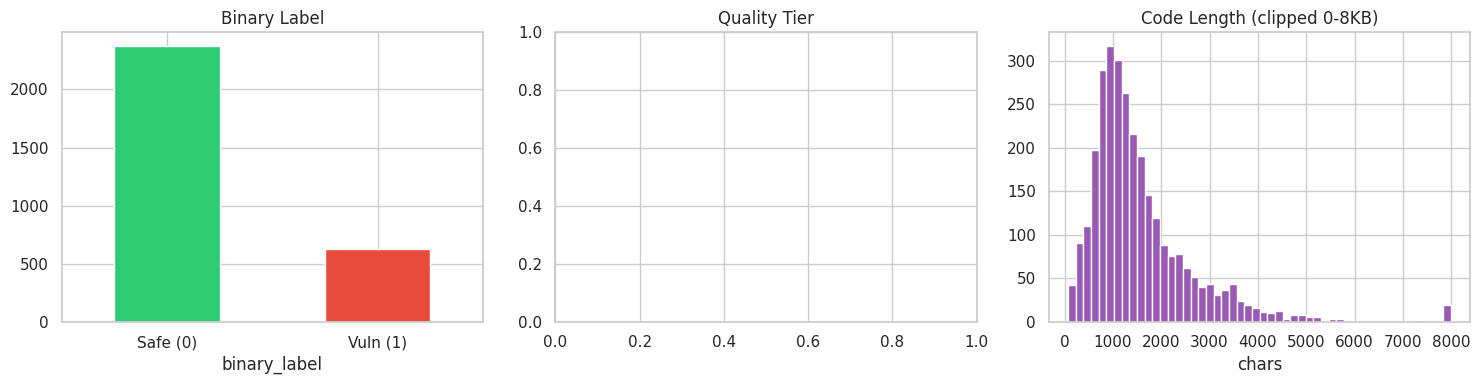


🎯 pos_rate=0.209 👉 auto focal_alpha=0.791


In [5]:
# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
eda_df["binary_label"].value_counts().plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Binary Label")
axes[0].set_xticklabels(["Safe (0)", "Vuln (1)"], rotation=0)

axes[1].set_title("Quality Tier")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

eda_df["code_len"].clip(0, 8000).hist(bins=50, ax=axes[2], color="#9b59b6")
axes[2].set_title("Code Length (clipped 0-8KB)")
axes[2].set_xlabel("chars")
plt.tight_layout()
plt.show()

# Auto focal_alpha dựa trên pos/neg ratio
pos_rate = eda_df["binary_label"].mean()
AUTO_FOCAL_ALPHA = 1 - pos_rate  # Focal ? ? neg_ratio
print(f"\n🎯 pos_rate={pos_rate:.3f} 👉 auto focal_alpha={AUTO_FOCAL_ALPHA:.3f}")

## 4. Cấu hình training (Fusion mode)


### 🚀 QUY TRÌNH HUẤN LUYỆN TỰ ĐỘNG 2 GIAI ĐOẠN - TÍCH HỢP 4 GIẢI PHÁP ĐỘT PHÁ

Notebook này triển khai **4 Giải pháp Cải tiến Toàn diện** giúp nhánh Fusion vượt trội hơn Semantic-Only:

1. 🥇 **Giải Pháp 1: Enriched Node Features (`node_encoder_type="hash"`)**
   - Không chỉ dựa vào 64 AST node types đơn thuần, mô hình tích hợp trực tiếp **nội dung mã nguồn (`node_texts`)** qua băm đặc trưng subtoken (`vocab_size=16384`) + Projection + LayerNorm.
   - Giúp Graph Encoder nắm bắt chính xác ý nghĩa các lời gọi hàm nguy hiểm (`strcpy`, `system`), tên biến, toán tử thay vì chỉ thấy cấu trúc rỗng.

2. 🥈 **Giải Pháp 2: Shared Pretrained CodeBERT Backbone (`node_encoder_type="shared_codebert"`)**
   - Chia sẻ trực tiếp không gian Word Embeddings của CodeBERT (50,265 tokens) cho Graph nodes.
   - Xóa bỏ triệt để *domain gap* giữa biểu diễn semantic và graph mà không tốn thêm GPU memory.

3. 🚀 **KẾT HỢP ĐỒNG THỜI CẢ GIẢI PHÁP 1 & 2 (`node_encoder_type="both"` hoặc `"hybrid"`)**
   - Tận dụng sức mạnh kép: vừa có tri thức ngôn ngữ lập trình phong phú từ CodeBERT (GP 2), vừa có đặc trưng subtoken băm thích ứng riêng cho task phát hiện lỗ hổng (GP 1).

4. 🥉 **Giải Pháp 3: FiLM Modulation & Additive Residual Skip (`fusion_level="pooled"`, `residual_alpha=0.2`)**
   - **Pooled Late Fusion / Token-level FiLM**: Điều biến representation qua FiLM (`(1 + gamma) * semantic + beta`), được bảo vệ chống tràn số FP16 và NaN.
   - **Additive Residual Skip**: Bật kết nối skip nhẹ cộng thẳng vector Semantic gốc để bảo toàn trọn vẹn sức mạnh pre-trained của CodeBERT, chống suy hao thông tin.

5. 🛡️ **Giải Pháp 4: Vulnerability-Aware Graph Features (`use_vul_features=True`)**
   - Tự động nhận diện Source (input, request), Sink (exec, eval, system), Sanitizer (escape, validate) trên PDG và mã hóa thành node feature vector bổ sung.

---
**Quy trình chạy:**
- Bấm **"Run All" một lần duy nhất**:
  - **Stage 1**: Huấn luyện Graph & FiLM (CodeBERT đóng băng 12 layers) đủ 12 epochs để Graph bắt kịp Semantic.
  - **Stage 2**: Tự động khôi phục Checkpoint tốt nhất Stage 1, mở khóa toàn bộ CodeBERT và tinh chỉnh end-to-end với LR siêu nhỏ (3e-6).


In [6]:
MODE = "fusion"
MAX_LEN = 512
BATCH_SIZE = 64                 # Tối ưu cho T4 16GB: VRAM ~6-7GB, tốc độ x2 so với batch 32
GRAD_ACCUM = 1
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
FOCAL_ALPHA = AUTO_FOCAL_ALPHA
FOCAL_GAMMA = 2.0
NUM_WORKERS = 4                 # 2 workers nạp trước dữ liệu song song (chống GPU starvation)
USE_AMP = True
TUNE_THRESHOLD = True  # Auto tune threshold tren val set

# --- CAU HINH STAGE 1 (Warm-up Graph & FiLM) ---
EPOCHS_STAGE1 = 12             # Tang len 12 de Graph du thoi gian hoi tu
PATIENCE_STAGE1 = 5
LR_STAGE1_GRAPH = 1.2e-4      # LR on dinh va du manh cho Graph với batch 64
LR_STAGE1_HEAD = 1.8e-4       # On dinh cho FiLM & BinaryHead (tranh bung no FP16)

# --- CAU HINH STAGE 2 (End-to-End Co-Adaptation) ---
EPOCHS_STAGE2 = 8
PATIENCE_STAGE2 = 4
LR_STAGE2_BACKBONE = 3.0e-6   # LR rat nho cho CodeBERT de giu tri thuc cu
LR_STAGE2_GRAPH = 3.0e-5      # Giam nhe cho Graph
LR_STAGE2_HEAD = 5.0e-5       # Giam nhe cho Head

# Duong dan checkpoint Semantic-Only da luu tren Kaggle (hoac local)
SEMANTIC_CKPT_PATH = Path("/kaggle/input/datasets/nhtqu1234/vul-sem-checkpoint/best.pt")

STAGE1_RESUME_PATH = Path("/kaggle/input/datasets/nhtqu1234/stage1_fusion/stage1_best.pt")
STAGE2_RESUME_PATH = Path("/kaggle/input/datasets/nhtqu1234/stage2-fusion/stage2_best.pt")

SEMANTIC_CFG = {
    "backbone": "microsoft/codebert-base",
    "output_dim": 256,
    "freeze_layers": 12,  # Khoi dau Stage 1: Dong bang toan bo 12 layer cua CodeBERT
    "dropout": 0.1,
    "pooling": "last",
    "gradient_checkpointing": False,
    "use_fp16": True,
}

GRAPH_CFG = {
    "node_feature_dim": 128,
    "hidden_dim": 256,
    "output_dim": 256,
    "num_layers": 3,
    "num_heads": 8,
    "num_edge_types": 5,
    "dropout": 0.2,
    "node_encoder_type": "both",   # SU DUNG DONG THOI CA GIAI PHAP 1 & 2
    "text_vocab_size": 16384,
    "combine_mode": "add",
    "use_vul_features": True,
}

FUSION_CFG = {
    "hidden_dim": 256,
    "num_heads": 8,
    "num_layers": 2,
    "dropout": 0.1,
    "combine": "film",
    "fusion_level": "pooled",
    "residual_alpha": 0.2,
}

HEAD_CFG = {
    "binary": {"hidden_dim": 128, "dropout": 0.2},
}

CKPT_DIR = Path("/kaggle/working/models/checkpoints/fusion") if IS_KAGGLE else REPO_DIR / "models/checkpoints/fusion"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Mode: {MODE} | Batch Size: {BATCH_SIZE} | Workers: {NUM_WORKERS} | Combine: {FUSION_CFG['combine']} | Fusion Level: {FUSION_CFG['fusion_level']}")
print(f"Graph Node Encoder: {GRAPH_CFG['node_encoder_type']} (Enriched Node Features: Hybrid GP1 + GP2)")
print(f"Vulnerability Node Features: {GRAPH_CFG.get('use_vul_features', True)} (GP4: Source/Sink/Sanitizer)")
print(f"Residual Alpha (FiLM): {FUSION_CFG['residual_alpha']}")
print(f"Stage 1: {EPOCHS_STAGE1} Epochs (CodeBERT Frozen, Graph LR: {LR_STAGE1_GRAPH}, Head LR: {LR_STAGE1_HEAD})")
print(f"Stage 2: {EPOCHS_STAGE2} Epochs (Full Fine-tuning, CodeBERT LR: {LR_STAGE2_BACKBONE})")


Mode: fusion | Batch Size: 64 | Workers: 4 | Combine: film | Fusion Level: pooled
Graph Node Encoder: both (Enriched Node Features: Hybrid GP1 + GP2)
Vulnerability Node Features: True (GP4: Source/Sink/Sanitizer)
Residual Alpha (FiLM): 0.2
Stage 1: 12 Epochs (CodeBERT Frozen, Graph LR: 0.00012, Head LR: 0.00018)
Stage 2: 8 Epochs (Full Fine-tuning, CodeBERT LR: 3e-06)


## 5. Build model + load datasets

In [7]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

model = VulHunterModel(
    mode=MODE,
    semantic_config=SEMANTIC_CFG,
    graph_config=GRAPH_CFG,
    fusion_config=FUSION_CFG,
    head_config=HEAD_CFG,
)
model.to(device)

# Lay thong tin truc tiep tu model (an toan tuyet doi)
node_enc = getattr(getattr(model, 'graph_encoder', None), 'node_encoder_type', GRAPH_CFG.get('node_encoder_type', 'both'))
has_vul_f = getattr(getattr(model, 'graph_encoder', None), 'vul_features', None) is not None
fusion_lvl = getattr(model, 'fusion_level', FUSION_CFG.get('fusion_level', 'pooled'))
res_alpha = getattr(model, '_fusion_residual_alpha', FUSION_CFG.get('residual_alpha', 0.2))

print(f"✅ Giai phap 1 & 2: Node Features ({node_enc}) da kich hoat")
print(f"✅ Giai phap 3: FiLM Fusion ({fusion_lvl}, residual_alpha={res_alpha}) da kich hoat")
print(f"✅ Giai phap 4: Vulnerability Features (Source/Sink/Sanitizer: {has_vul_f}) da kich hoat")

# Tu dong nap trong so Semantic-Only da fine-tune vao CodeBERT
if SEMANTIC_CKPT_PATH.exists():
    print(f"\n📥 Nap trong so Semantic-Only tu {SEMANTIC_CKPT_PATH}...")
    ckpt = torch.load(SEMANTIC_CKPT_PATH, map_location=device, weights_only=False)
    sem_weights = {k.split("semantic_encoder.")[-1]: v 
                   for k, v in ckpt["model_state_dict"].items() if "semantic_encoder." in k}
    if sem_weights:
        missing, unexpected = model.semantic_encoder.load_state_dict(sem_weights, strict=False)
        print(f"✅ Da nap thanh cong {len(sem_weights)} Layers Semantic! (Missing: {len(missing)} keys)")
    else:
        print("⚠️ Khong tim thay trong so Semantic trong file checkpoint!")
else:
    print(f"ℹ️ Khong tim thay {SEMANTIC_CKPT_PATH}, dung CodeBERT goc tu HuggingFace.")

# Khoi tao zero-init cho FiLM gamma & beta (Identity Mapping khoi dau, bao ve semantic features)
if hasattr(model, "fusion") and hasattr(model.fusion, "film_gamma"):
    nn.init.zeros_(model.fusion.film_gamma[-1].weight)
    nn.init.zeros_(model.fusion.film_gamma[-1].bias)
    nn.init.zeros_(model.fusion.film_beta[-1].weight)
    nn.init.zeros_(model.fusion.film_beta[-1].bias)
    print("✅ Da khoi tao FiLM gamma & beta ve 0 (Identity mapping bao ve Semantic signal)")

# Trainable params float32 cho AMP GradScaler
for p in model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"\n🚀 Model [{MODE}] Stage 1 ── Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)\n")


config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Giai phap 1 & 2: Node Features (both) da kich hoat
✅ Giai phap 3: FiLM Fusion (pooled, residual_alpha=0.2) da kich hoat
✅ Giai phap 4: Vulnerability Features (Source/Sink/Sanitizer: True) da kich hoat

📥 Nap trong so Semantic-Only tu /kaggle/input/datasets/nhtqu1234/vul-sem-checkpoint/best.pt...
✅ Da nap thanh cong 205 Layers Semantic! (Missing: 0 keys)
✅ Da khoi tao FiLM gamma & beta ve 0 (Identity mapping bao ve Semantic signal)

🚀 Model [fusion] Stage 1 ── Trainable: 7,689,988 / 131,745,028 (5.84%)



In [8]:
# Build dataloaders vá»›i Zero-RAM Lazy Indexing vÃ  Multi-worker Prefetching
# Dataset dÃ¹ng chung _LazyGraphDict (~15MB RAM total), xÃ³a bá» 100% hiá»‡n tÆ°á»£ng trÃ n RAM vÃ  swapping
train_ds = VulHunterDataset(data_path=TRAIN_JSONL, max_length=MAX_LEN, graph_data_path=GRAPH_PATH, tokenizer_name="microsoft/codebert-base")
val_ds   = VulHunterDataset(data_path=VAL_JSONL,   max_length=MAX_LEN, graph_data_path=GRAPH_PATH, tokenizer_name="microsoft/codebert-base")
test_ds  = VulHunterDataset(data_path=TEST_JSONL,  max_length=MAX_LEN, graph_data_path=GRAPH_PATH, tokenizer_name="microsoft/codebert-base")

from functools import partial
collate_fn_padded = partial(collate_fn, pad_to_multiple_of=8)

loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "persistent_workers": (NUM_WORKERS > 0),
    "prefetch_factor": 2 if NUM_WORKERS > 0 else None,
}
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_padded, **loader_kwargs)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False, collate_fn=collate_fn_padded, **loader_kwargs)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False, collate_fn=collate_fn_padded, **loader_kwargs)

print(f"Train: {len(train_ds):} | Val: {len(val_ds):} | Test: {len(test_ds):}")

# Sample
sample = next(iter(train_loader))
print("\nSample keys:", list(sample.keys()))
print(f"  input_ids: {sample['input_ids'].shape}")
print(f"  binary_labels: {sample['binary_labels'].tolist()[:8]}")
if "batch" in sample:
    print(f"  graph_batch: {sample['batch'].shape}, nodes={len(sample['node_types'])}")


Train: 111902 | Val: 13987 | Test: 13990

Sample keys: ['input_ids', 'attention_mask', 'binary_labels', 'codes', 'node_types', 'node_texts', 'node_is_source', 'node_is_sink', 'node_is_sanitizer', 'batch', 'edge_index', 'edge_type', 'sample_ids']
  input_ids: torch.Size([64, 512])
  binary_labels: [0, 0, 0, 0, 0, 0, 0, 0]
  graph_batch: torch.Size([4791]), nodes=4791


In [9]:
# Sanity check forward pass
model.eval()
sample = next(iter(val_loader))
with torch.no_grad():
    kwargs = {
        "input_ids": sample["input_ids"].to(device),
        "attention_mask": sample["attention_mask"].to(device),
        "node_types": sample["node_types"],
        "node_texts": sample.get("node_texts"),
        "node_is_source": sample.get("node_is_source"),
        "node_is_sink": sample.get("node_is_sink"),
        "node_is_sanitizer": sample.get("node_is_sanitizer"),
        "edge_index": sample["edge_index"].to(device),
        "edge_type": sample["edge_type"].to(device),
        "batch": sample["batch"].to(device),
    }
    out = model(**kwargs)
print(f"binary_logits: {out.binary_logits.shape}")
print(f"fused_embedding: {out.fused_embedding.shape}")
print("✅ Forward pass OK")
model.train()


binary_logits: torch.Size([128, 1])
fused_embedding: torch.Size([128, 256])
✅ Forward pass OK


VulHunterModel(
  (semantic_encoder): SemanticEncoder(
    (backbone): RobertaModel(
      (embeddings): RobertaEmbeddings(
        (word_embeddings): Embedding(50265, 768, padding_idx=1)
        (token_type_embeddings): Embedding(1, 768)
        (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (position_embeddings): Embedding(514, 768, padding_idx=1)
      )
      (encoder): RobertaEncoder(
        (layer): ModuleList(
          (0-11): 12 x RobertaLayer(
            (attention): RobertaAttention(
              (self): RobertaSelfAttention(
                (query): Linear(in_features=768, out_features=768, bias=True)
                (key): Linear(in_features=768, out_features=768, bias=True)
                (value): Linear(in_features=768, out_features=768, bias=True)
                (dropout): Dropout(p=0.1, inplace=False)
              )
              (output): RobertaSelfOutput(
                (dense): Line

## 6. Setup optimizer factory + criterion

In [10]:
# Criterion: Binary focal loss an toan voi clamp tranh overflow trong FP16
base_criterion = BinaryClassificationLoss(focal_alpha=FOCAL_ALPHA, focal_gamma=FOCAL_GAMMA)

def criterion(binary_logits, binary_targets):
    # Ep logits ve float32 va clamp [-15, 15] tranh triet de overflow trong FP16
    safe_logits = binary_logits.float().clamp(-15.0, 15.0)
    return base_criterion(binary_logits=safe_logits, binary_targets=binary_targets)

def setup_optimizer_and_scheduler(model, lr_backbone, lr_graph, lr_head, epochs):
    """Ham tao Optimizer & Scheduler doc lap cho tung Stage."""
    backbone_params, graph_params, head_params = [], [], []
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    for name, p in base_model.named_parameters():
        if not p.requires_grad:
            continue
        if "semantic_encoder.backbone" in name:
            backbone_params.append(p)
        elif "graph_encoder" in name:
            graph_params.append(p)
        else:
            head_params.append(p)

    param_groups = []
    if backbone_params and lr_backbone > 0:
        param_groups.append({"params": backbone_params, "lr": lr_backbone})
    if graph_params and lr_graph > 0:
        param_groups.append({"params": graph_params, "lr": lr_graph})
    if head_params and lr_head > 0:
        param_groups.append({"params": head_params, "lr": lr_head})

    use_fused_adamw = (
        torch.cuda.is_available()
        and hasattr(torch.optim, "AdamW")
        and "fused" in torch.optim.AdamW.__init__.__code__.co_varnames
    )
    if use_fused_adamw:
        optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY, fused=True)
    else:
        optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)

    steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
    total_steps = steps_per_epoch * epochs
    # Warmup ngan hon (~600 steps) de mo hinh hoi tu deu, khong vot vot qua cao o dau Epoch 2
    warmup_steps = min(800, max(50, int(steps_per_epoch * 0.2)))

    def lr_lambda(step):
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress))))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and torch.cuda.is_available())
    
    print(f"  Optimizer: {len(backbone_params)} backbone ({lr_backbone:.1e}) + {len(graph_params)} graph ({lr_graph:.1e}) + {len(head_params)} head ({lr_head:.1e})")
    print(f"  Total steps: {total_steps} | Warmup: {warmup_steps}")
    return optimizer, scheduler, scaler

## 7. STAGE 1: Warm-up Graph & FiLM (CodeBERT Dong Bang)

In [11]:
  def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch, total_epochs=EPOCHS_STAGE1):
    model.train()
    total_loss = 0.0
    valid_steps = 0
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}/{total_epochs} [Train]", leave=False)
    for step, batch in enumerate(pbar):
        kwargs = {
            "input_ids": batch["input_ids"].to(device, non_blocking=True),
            "attention_mask": batch["attention_mask"].to(device, non_blocking=True),
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "node_is_source": batch.get("node_is_source"),
            "node_is_sink": batch.get("node_is_sink"),
            "node_is_sanitizer": batch.get("node_is_sanitizer"),
            "edge_index": batch["edge_index"].to(device, non_blocking=True),
            "edge_type": batch["edge_type"].to(device, non_blocking=True),
            "batch": batch["batch"].to(device, non_blocking=True),
        }
        targets = batch["binary_labels"].to(device, non_blocking=True)
        is_accumulating = ((step + 1) % GRAD_ACCUM != 0) and ((step + 1) != len(loader))
        
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
                binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
                losses = criterion(binary_logits=binary_logits, binary_targets=targets)
                loss = losses["total"] / GRAD_ACCUM
            
            # Kiem tra loss huu han truoc khi backward (chong nhiem doc NaN vao gradient)
            if not torch.isfinite(loss):
                print(f"\n⚠️ Canh bao: Loss khong huu han tai step {step+1}, bo qua batch de bao ve trong so!")
                optimizer.zero_grad(set_to_none=True)
                continue
                
            scaler.scale(loss).backward()
        else:
            out = model(**kwargs)
            binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
            losses = criterion(binary_logits=binary_logits, binary_targets=targets)
            loss = losses["total"] / GRAD_ACCUM
            
            if not torch.isfinite(loss):
                print(f"\n⚠️ Canh bao: Loss khong huu han tai step {step+1}, bo qua batch!")
                optimizer.zero_grad(set_to_none=True)
                continue
                
            loss.backward()

        if not is_accumulating:
            if USE_AMP and scaler is not None:
                scaler.unscale_(optimizer)
                # Kiem tra grad norm truoc khi step optimizer
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if torch.isfinite(grad_norm):
                    scaler.step(optimizer)
                else:
                    print(f"\n⚠️ Canh bao: Gradient norm khong huu han ({grad_norm}) tai step {step+1}, bo qua optimizer step!")
                    optimizer.zero_grad(set_to_none=True)
                scaler.update()
            else:
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if torch.isfinite(grad_norm):
                    optimizer.step()
                else:
                    optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            
        total_loss += loss.item() * GRAD_ACCUM
        valid_steps += 1
        if (step + 1) % 10 == 0 or step == len(loader) - 1:
            avg_loss = total_loss / max(valid_steps, 1)
            pbar.set_postfix({'loss': f"{avg_loss:.4f}", 'lr': f"{optimizer.param_groups[0]['lr']:.2e}"})
            
    return total_loss / max(valid_steps, 1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_prob = [], []
    pbar = tqdm(loader, desc="Evaluating", leave=False)
    for batch in pbar:
        kwargs = {
            "input_ids": batch["input_ids"].to(device),
            "attention_mask": batch["attention_mask"].to(device),
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "node_is_source": batch.get("node_is_source"),
            "node_is_sink": batch.get("node_is_sink"),
            "node_is_sanitizer": batch.get("node_is_sanitizer"),
            "edge_index": batch["edge_index"].to(device),
            "edge_type": batch["edge_type"].to(device),
            "batch": batch["batch"].to(device),
        }
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
        else:
            out = model(**kwargs)
        binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
        # Luon dung float32 cho sigmoid de du doan chinh xac tuyet doi
        p = torch.sigmoid(binary_logits.squeeze(-1).float())
        p = torch.nan_to_num(p, nan=0.5)
        y_true.extend(batch["binary_labels"].tolist())
        y_prob.extend(p.cpu().tolist())
    return np.array(y_true), np.array(y_prob)

print("✅ Training functions defined (with Numerical Stability Guards & Vulnerability Features)")


✅ Training functions defined (with Numerical Stability Guards & Vulnerability Features)


In [12]:
print("=" * 65)
print("🚀 BAT DAU STAGE 1: HUAN LUYEN GRAPH & FiLM (CODEBERT DONG BANG)")
print("=" * 65)

# Đảm bảo thư mục lưu trữ checkpoint tồn tại
CKPT_DIR.mkdir(parents=True, exist_ok=True)

optimizer_s1, scheduler_s1, scaler_s1 = setup_optimizer_and_scheduler(
    model, lr_backbone=0.0, lr_graph=LR_STAGE1_GRAPH, lr_head=LR_STAGE1_HEAD, epochs=EPOCHS_STAGE1
)

start_epoch = 0
best_f1_stage1 = 0.0
best_thr_stage1 = 0.5
patience_counter = 0
history_stage1 = []

# ==============================================================================
# 🔍 CƠ CHẾ AUTO-DISCOVERY: TỰ ĐỘNG TÌM FILE CHECKPOINT TRONG /kaggle/input
# ==============================================================================
target_ckpt_file = None

# 1. Thử kiểm tra đường dẫn thủ công nếu có khai báo
manual_path = globals().get("STAGE1_RESUME_PATH", None)
if manual_path:
    p = Path(manual_path)
    if p.is_file():
        target_ckpt_file = p
        print(f"🎯 Tìm thấy file theo đường dẫn chỉ định: {target_ckpt_file}")
    else:
        print(f"⚠️ Cảnh báo: Đường dẫn STAGE1_RESUME_PATH không tồn tại: {p.resolve()}")

# 2. Nếu đường dẫn thủ công sai, tự động quét tìm trong /kaggle/input và thư mục working
if target_ckpt_file is None:
    print("🔎 Đang tự động quét tìm file stage1 checkpoint trong /kaggle/input...")
    search_dirs = [Path("/kaggle/input"), CKPT_DIR]
    candidates = []
    for d in search_dirs:
        if d.exists():
            candidates.extend(list(d.rglob("*stage1*best*.pt")))
            candidates.extend(list(d.rglob("*stage1*.pt")))
    
    # Lọc bỏ raw-data
    valid_candidates = [c for c in candidates if "raw-data" not in str(c).lower() and c.is_file()]
    if valid_candidates:
        target_ckpt_file = valid_candidates[0]
        print(f"🎯 AUTO-DETECT: Đã tự động tìm thấy file checkpoint tại:\n   --> {target_ckpt_file}")
    else:
        print("❌ Không tìm thấy file checkpoint stage1 nào trong hệ thống!")
        if Path("/kaggle/input").exists():
            print("   Danh sách các file thực tế đang có trong /kaggle/input:")
            all_files = [f for f in Path("/kaggle/input").rglob("*") if f.is_file()]
            for f in all_files[:10]:
                print(f"     - {f}")
            if len(all_files) > 10:
                print(f"     ... và {len(all_files) - 10} files khác.")

# ==============================================================================
# 🔄 NẠP VÀ PHỤC HỒI TRẠNG THÁI CHECKPOINT
# ==============================================================================
if target_ckpt_file is not None and target_ckpt_file.exists():
    print(f"\n🔄 Đang nạp checkpoint từ {target_ckpt_file}...")
    ckpt_s1 = torch.load(target_ckpt_file, map_location=device, weights_only=False)
    
    # In thông tin các keys có trong checkpoint để chẩn đoán
    if isinstance(ckpt_s1, dict):
        print(f"  🔍 Cấu trúc Checkpoint chứa các keys: {list(ckpt_s1.keys())}")
    
    # 1. Khôi phục trọng số Model
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    if isinstance(ckpt_s1, dict) and "model_state_dict" in ckpt_s1:
        base_model.load_state_dict(ckpt_s1["model_state_dict"], strict=False)
        print("  ✅ Đã nạp thành công Model weights.")
    elif isinstance(ckpt_s1, dict):
        # Trường hợp file chỉ lưu trực tiếp state_dict
        base_model.load_state_dict(ckpt_s1, strict=False)
        print("  ✅ Đã nạp trực tiếp weights từ state_dict.")

    # Luôn đồng bộ sang CKPT_DIR / 'stage1_best.pt' cho Stage 2
    target_best_path = CKPT_DIR / "stage1_best.pt"
    if target_ckpt_file.resolve() != target_best_path.resolve():
        shutil.copy2(target_ckpt_file, target_best_path)
        print(f"  💾 Đã đồng bộ checkpoint sang {target_best_path}")

    # 2. Khôi phục Epoch và chỉ số thống kê (Format-Agnostic)
    if isinstance(ckpt_s1, dict):
        if "epoch" in ckpt_s1:
            start_epoch = int(ckpt_s1["epoch"])
        elif "current_epoch" in ckpt_s1:
            start_epoch = int(ckpt_s1["current_epoch"])
        elif "history" in ckpt_s1 and len(ckpt_s1["history"]) > 0:
            start_epoch = len(ckpt_s1["history"])
        else:
            start_epoch = 0

        best_f1_stage1 = float(ckpt_s1.get("best_f1", 0.0))
        best_thr_stage1 = float(ckpt_s1.get("best_threshold", 0.5))
        patience_counter = 0  # Bắt đầu từ model tốt nhất -> reset patience
        history_stage1 = list(ckpt_s1.get("history", []))

    # 3. Khôi phục Optimizer State
    if isinstance(ckpt_s1, dict) and ckpt_s1.get("optimizer_state_dict") is not None:
        try:
            optimizer_s1.load_state_dict(ckpt_s1["optimizer_state_dict"])
            print("  ✅ Đã khôi phục Optimizer state.")
        except Exception as e:
            print(f"  ℹ️ Khởi tạo lại Optimizer state mới: {e}")

    # 4. Khôi phục hoặc TUA NHANH LR Scheduler
    if isinstance(ckpt_s1, dict) and ckpt_s1.get("scheduler_state_dict") is not None:
        try:
            scheduler_s1.load_state_dict(ckpt_s1["scheduler_state_dict"])
            print("  ✅ Đã khôi phục Scheduler state.")
        except Exception:
            pass
    elif start_epoch > 0:
        steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
        steps_done = min(start_epoch * steps_per_epoch, steps_per_epoch * EPOCHS_STAGE1)
        for _ in range(steps_done):
            scheduler_s1.step()
        current_lr = optimizer_s1.param_groups[0]["lr"]
        print(f"  ⏩ Đã đồng bộ LR Scheduler tới step {steps_done} (LR hiện tại: {current_lr:.2e}).")

    # 5. Khôi phục GradScaler
    if scaler_s1 is not None and isinstance(ckpt_s1, dict) and ckpt_s1.get("scaler_state_dict") is not None:
        try:
            scaler_s1.load_state_dict(ckpt_s1["scaler_state_dict"])
            print("  ✅ Đã khôi phục FP16 GradScaler.")
        except Exception:
            pass

    print(f"\n🚀 SẴN SÀNG TIẾP TỤC: Từ Epoch {start_epoch + 1}/{EPOCHS_STAGE1} (Best F1 trước: {best_f1_stage1:.4f})\n")

    if start_epoch >= EPOCHS_STAGE1:
        print(f"⚡ Stage 1 đã hoàn thành đủ {start_epoch}/{EPOCHS_STAGE1} epochs ở phiên trước!")
        print("➡️ Tự động bỏ qua vòng lặp Stage 1, chuyển thẳng sang Stage 2.\n")
else:
    print("\n🆕 Không nạp được checkpoint cũ, bắt đầu Stage 1 từ Epoch 1.")

# Nếu phát hiện đang cần Resume Stage 2 -> Tự động bỏ qua toàn bộ Stage 1!
if globals().get("STAGE2_RESUME_PATH") and Path(STAGE2_RESUME_PATH).exists():
    print("⏩ PHÁT HIỆN CHECKPOINT STAGE 2: Bỏ qua toàn bộ huấn luyện Stage 1 để vào thẳng Stage 2!")
    start_epoch = EPOCHS_STAGE1  # Đặt bằng max epoch để vòng lặp bên dưới không chạy lần nào

# --- VÒNG LẶP HUẤN LUYỆN STAGE 1 ---
for epoch in range(start_epoch, EPOCHS_STAGE1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer_s1, scheduler_s1, scaler_s1, epoch, total_epochs=EPOCHS_STAGE1)
    val_y, val_prob = evaluate(model, val_loader)
    elapsed = time.time() - t0

    if TUNE_THRESHOLD and len(val_y) > 0:
        thr, m = find_best_threshold(val_y, val_prob)
    else:
        thr = 0.5
        preds = (val_prob >= thr).astype(int)
        m = binary_metrics(val_y, preds, val_prob, threshold=thr)
    val_f1 = m.f1

    print(f"\nStage 1 - Epoch {epoch+1}/{EPOCHS_STAGE1} ({elapsed:.1f}s)")
    print(f"  Train loss: {train_loss:.4f}")
    print(f"  Val: F1={val_f1:.4f} | P={m.precision:.4f} | R={m.recall:.4f} | AUC={m.auc:.4f} | thr={thr:.2f}")

    history_stage1.append({
        "stage": 1, "epoch": epoch + 1, "train_loss": train_loss,
        "val_f1": val_f1, "val_metrics": m.to_dict(), "threshold": thr, "elapsed": elapsed,
    })

    # Cấu trúc lưu trữ đầy đủ cho các phiên sau
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    checkpoint_data = {
        "stage": 1,
        "epoch": epoch + 1,
        "model_state_dict": {k: v.cpu() for k, v in base_model.state_dict().items()},
        "optimizer_state_dict": optimizer_s1.state_dict(),
        "scheduler_state_dict": scheduler_s1.state_dict(),
        "scaler_state_dict": scaler_s1.state_dict() if scaler_s1 else None,
        "best_f1": best_f1_stage1,
        "best_threshold": best_thr_stage1,
        "patience_counter": patience_counter,
        "history": history_stage1,
    }

    torch.save(checkpoint_data, CKPT_DIR / "stage1_last.pt")

    if val_f1 > best_f1_stage1:
        best_f1_stage1 = val_f1
        best_thr_stage1 = thr
        patience_counter = 0
        checkpoint_data["best_f1"] = best_f1_stage1
        checkpoint_data["best_threshold"] = best_thr_stage1
        checkpoint_data["patience_counter"] = 0
        torch.save(checkpoint_data, CKPT_DIR / "stage1_best.pt")
        print(f"  ✅ Saved Best Stage 1 (F1={best_f1_stage1:.4f}, thr={best_thr_stage1:.2f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE_STAGE1:
            print(f"\n⏹ Early stopping Stage 1 sau {PATIENCE_STAGE1} epochs khong cai thien.")
            break
    torch.cuda.empty_cache()

print(f"\n🏁 HOAN THANH STAGE 1! Best Val F1 = {best_f1_stage1:.4f} (luu tai stage1_best.pt)\n")

🚀 BAT DAU STAGE 1: HUAN LUYEN GRAPH & FiLM (CODEBERT DONG BANG)
  Optimizer: 2 backbone (0.0e+00) + 33 graph (1.2e-04) + 86 head (1.8e-04)
  Total steps: 20988 | Warmup: 349
⚠️ Cảnh báo: Đường dẫn STAGE1_RESUME_PATH không tồn tại: /kaggle/input/datasets/nhtqu1234/stage1_fusion/stage1_best.pt
🔎 Đang tự động quét tìm file stage1 checkpoint trong /kaggle/input...
🎯 AUTO-DETECT: Đã tự động tìm thấy file checkpoint tại:
   --> /kaggle/input/datasets/nhtqu1234/stage1-fusion/stage1_best.pt

🔄 Đang nạp checkpoint từ /kaggle/input/datasets/nhtqu1234/stage1-fusion/stage1_best.pt...
  🔍 Cấu trúc Checkpoint chứa các keys: ['stage', 'epoch', 'model_state_dict', 'best_f1', 'best_threshold', 'history']
  ✅ Đã nạp thành công Model weights.
  💾 Đã đồng bộ checkpoint sang /kaggle/working/models/checkpoints/fusion/stage1_best.pt
  ⏩ Đã đồng bộ LR Scheduler tới step 10494 (LR hiện tại: 6.16e-05).

🚀 SẴN SÀNG TIẾP TỤC: Từ Epoch 7/12 (Best F1 trước: 0.7467)

⏩ PHÁT HIỆN CHECKPOINT STAGE 2: Bỏ qua toàn bộ hu

## 8. STAGE 2 SETUP: Mo Khoa CodeBERT & Khoi Phuc Stage 1

In [13]:
print("=" * 65)
print("🚀 CHUYEN GIAO SANG STAGE 2: MO KHOA CODEBERT VA KHOI PHUC STAGE 1")
print("=" * 65)

# --- 1. DỌN DẸP TRIỆT ĐỂ BỘ NHỚ VRAM TỪ STAGE 1 ---
if "optimizer_s1" in globals(): del optimizer_s1
if "scheduler_s1" in globals(): del scheduler_s1
if "scaler_s1" in globals(): del scaler_s1

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()
print("🧹 Đã dọn dẹp bộ nhớ đệm và giải phóng các buffers từ Stage 1.")

# --- 2. NẠP LẠI CHECKPOINT TỐT NHẤT TỪ STAGE 1 ---
stage1_ckpt_path = CKPT_DIR / "stage1_best.pt"
if stage1_ckpt_path.exists():
    print(f"🔄 Nạp lại checkpoint tốt nhất của Stage 1 từ {stage1_ckpt_path}...")
    s1_ckpt = torch.load(stage1_ckpt_path, map_location=device, weights_only=False)
    base_model = getattr(model, "module", model)
    base_model.load_state_dict(s1_ckpt["model_state_dict"], strict=False)
    best_f1_stage1 = s1_ckpt.get("best_f1", 0.0)
    best_thr_stage1 = s1_ckpt.get("best_threshold", 0.5)
    print(f"  ✅ Đã nạp thành công Stage 1 checkpoint (Best F1: {best_f1_stage1:.4f})")
else:
    print("⚠️ Cảnh báo: Không tìm thấy stage1_best.pt, tiếp tục với trọng số hiện tại.")

# --- 3. MỞ KHÓA TOÀN BỘ CODEBERT ---
base_model = model.module if isinstance(model, nn.DataParallel) else model
for p in base_model.parameters():
    p.requires_grad = True

SEMANTIC_CFG["freeze_layers"] = 0

# --- 4. BẬT GRADIENT CHECKPOINTING CHO CODEBERT (VŨ KHÍ GIẢM 65% VRAM ACTIVATIONS) ---
if hasattr(base_model, "semantic_encoder") and hasattr(base_model.semantic_encoder, "backbone"):
    backbone = base_model.semantic_encoder.backbone
    if hasattr(backbone, "enable_input_require_grads"):
        backbone.enable_input_require_grads()
    if hasattr(backbone, "gradient_checkpointing_enable"):
        backbone.gradient_checkpointing_enable()
        print("  ⚡ Đã bật Gradient Checkpointing cho CodeBERT (Chống OOM Transformer).")

# Float32 check cho AMP
for p in model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"  🔓 Đã mở khóa CodeBERT! 📊 Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")

# --- 5. ĐIỀU CHỈNH BATCH SIZE & GRAD ACCUM CHO STAGE 2 ---
# Effective Batch Size = 16 * 4 = 64 (Giữ nguyên vẹn 100% như Stage 1, nhưng VRAM giảm 4 lần)
BATCH_SIZE = 16
GRAD_ACCUM = 4

train_loader = DataLoader(
    train_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    collate_fn=collate_fn_padded, 
    **loader_kwargs
)
val_loader = DataLoader(
    val_ds, 
    batch_size=BATCH_SIZE * 2,  # 32 samples / batch (thay vì 128)
    shuffle=False, 
    collate_fn=collate_fn_padded, 
    **loader_kwargs
)
print(f"  📦 DataLoader Stage 2: Batch Size = {BATCH_SIZE}, Grad Accum = {GRAD_ACCUM} (Effective Batch = {BATCH_SIZE * GRAD_ACCUM})")

# --- 6. KHỞI TẠO OPTIMIZER & SCHEDULER CHO STAGE 2 ---
optimizer_s2, scheduler_s2, scaler_s2 = setup_optimizer_and_scheduler(
    model, 
    lr_backbone=LR_STAGE2_BACKBONE, 
    lr_graph=LR_STAGE2_GRAPH, 
    lr_head=LR_STAGE2_HEAD, 
    epochs=EPOCHS_STAGE2
)
# Xóa rác lần cuối để VRAM ở trạng thái tinh khiết nhất trước khi bước vào Epoch 1
gc.collect()
torch.cuda.empty_cache()
print("\u2705 Stage 2 da san sang huan luyen!")

🚀 CHUYEN GIAO SANG STAGE 2: MO KHOA CODEBERT VA KHOI PHUC STAGE 1
🧹 Đã dọn dẹp bộ nhớ đệm và giải phóng các buffers từ Stage 1.
🔄 Nạp lại checkpoint tốt nhất của Stage 1 từ /kaggle/working/models/checkpoints/fusion/stage1_best.pt...
  ✅ Đã nạp thành công Stage 1 checkpoint (Best F1: 0.7467)
  ⚡ Đã bật Gradient Checkpointing cho CodeBERT (Chống OOM Transformer).
  🔓 Đã mở khóa CodeBERT! 📊 Trainable: 131,745,028 / 131,745,028 (100.00%)
  📦 DataLoader Stage 2: Batch Size = 16, Grad Accum = 4 (Effective Batch = 64)
  Optimizer: 199 backbone (3.0e-06) + 33 graph (3.0e-05) + 86 head (5.0e-05)
  Total steps: 13992 | Warmup: 349
✅ Stage 2 da san sang huan luyen!


## 9. STAGE 2: End-to-End Co-Adaptation Training Loop

In [14]:
print("=" * 65)
print("🚀  BAT DAU STAGE 2: HUAN LUYEN TOAN MANG END-TO-END (CO-ADAPTATION)")
print("=" * 65)

start_epoch_s2 = 0
best_f1_final = globals().get("best_f1_stage1", 0.0)
best_thr_final = globals().get("best_thr_stage1", 0.5)
patience_counter = 0
history_stage2 = []

# --- 1. TỰ ĐỘNG TÌM KIẾM VÀ NẠP CHECKPOINT STAGE 2 ---
target_s2_file = None
manual_s2_path = globals().get("STAGE2_RESUME_PATH", None)
if manual_s2_path and Path(manual_s2_path).is_file():
    target_s2_file = Path(manual_s2_path)
    print(f"🎯 Tìm thấy Checkpoint Stage 2 theo đường dẫn chỉ định: {target_s2_file}")
elif manual_s2_path:
    print(f"⚠️ Cảnh báo: STAGE2_RESUME_PATH không tồn tại: {manual_s2_path}")
# Tự động quét trong /kaggle/input nếu đường dẫn tay bị sai
if target_s2_file is None and Path("/kaggle/input").exists():
    candidates = list(Path("/kaggle/input").rglob("*stage2*.pt")) + \
                 list(Path("/kaggle/input").rglob("*best*.pt"))
    valid_s2 = [c for c in candidates if "raw-data" not in str(c).lower() and "stage1" not in str(c).lower() and c.is_file()]
    if valid_s2:
        target_s2_file = valid_s2[0]
        print(f"🎯 AUTO-DETECT: Đã tự động tìm thấy Checkpoint Stage 2 tại:\n   --> {target_s2_file}")
# Nạp và phục hồi trạng thái Stage 2
if target_s2_file is not None and target_s2_file.exists():
    print(f"\n🔄 Đang khôi phục Stage 2 từ: {target_s2_file}...")
    ckpt_s2 = torch.load(target_s2_file, map_location=device, weights_only=False)
    
    # 1.1 Khôi phục trọng số mô hình
    base_model = getattr(model, "module", model)
    if isinstance(ckpt_s2, dict) and "model_state_dict" in ckpt_s2:
        base_model.load_state_dict(ckpt_s2["model_state_dict"], strict=False)
        print("  ✅ Đã nạp thành công trọng số Model cho Stage 2.")
    elif isinstance(ckpt_s2, dict):
        base_model.load_state_dict(ckpt_s2, strict=False)
        print("  ✅ Đã nạp trực tiếp weights từ state_dict.")
    # 1.2 Khôi phục Optimizer State của Stage 2 (Cực kỳ quan trọng cho 125M tham số CodeBERT)
    if isinstance(ckpt_s2, dict) and ckpt_s2.get("optimizer_state_dict") is not None:
        try:
            optimizer_s2.load_state_dict(ckpt_s2["optimizer_state_dict"])
            print("  ✅ Đã khôi phục Optimizer state (AdamW) của Stage 2.")
        except Exception as e:
            print(f"  ℹ️ Khởi tạo Optimizer state mới: {e}")
    # 1.3 Khôi phục hoặc Tua nhanh LR Scheduler của Stage 2
    start_epoch_s2 = ckpt_s2.get("epoch", 0) if isinstance(ckpt_s2, dict) else 0
    if isinstance(ckpt_s2, dict) and ckpt_s2.get("scheduler_state_dict") is not None:
        try:
            scheduler_s2.load_state_dict(ckpt_s2["scheduler_state_dict"])
            print("  ✅ Đã khôi phục Scheduler state.")
        except Exception:
            pass
    elif start_epoch_s2 > 0:
        steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
        steps_done = min(start_epoch_s2 * steps_per_epoch, steps_per_epoch * EPOCHS_STAGE2)
        for _ in range(steps_done):
            scheduler_s2.step()
        current_lr = optimizer_s2.param_groups[0]["lr"]
        print(f"  ⏩ Đã đồng bộ LR Scheduler Stage 2 tới step {steps_done} (LR: {current_lr:.2e}).")
    # 1.4 Khôi phục FP16 GradScaler
    if scaler_s2 is not None and isinstance(ckpt_s2, dict) and ckpt_s2.get("scaler_state_dict") is not None:
        try:
            scaler_s2.load_state_dict(ckpt_s2["scaler_state_dict"])
            print("  ✅ Đã khôi phục FP16 GradScaler.")
        except Exception:
            pass
    # 1.5 Khôi phục Epoch, Best F1, History
    if isinstance(ckpt_s2, dict):
        best_f1_final = float(ckpt_s2.get("best_f1", best_f1_final))
        best_thr_final = float(ckpt_s2.get("best_threshold", best_thr_final))
        patience_counter = int(ckpt_s2.get("patience_counter", 0))
        history_stage2 = list(ckpt_s2.get("history_stage2", []))
        if "history_stage1" in ckpt_s2:
            history_stage1 = list(ckpt_s2["history_stage1"])
    print(f"\n🚀 SẴN SÀNG TIẾP TỤC STAGE 2: Từ Epoch {start_epoch_s2 + 1}/{EPOCHS_STAGE2} (Best F1 trước: {best_f1_final:.4f}, Patience: {patience_counter}/{PATIENCE_STAGE2})\n")
    
    if start_epoch_s2 >= EPOCHS_STAGE2:
        print(f"⚡ Stage 2 đã hoàn thành đủ {start_epoch_s2}/{EPOCHS_STAGE2} epochs ở phiên trước!")
        print("➡️ Bỏ qua huấn luyện, chuyển thẳng xuống bước Đánh giá Test Set.\n")
else:
    print(f"\n🆕 Không có checkpoint Stage 2 cũ, bắt đầu Stage 2 từ Epoch 1 (Mục tiêu vượt qua Stage 1: F1={best_f1_final:.4f}).\n")
# --- 2. VÒNG LẶP HUẤN LUYỆN CHÍNH STAGE 2 ---
for epoch in range(start_epoch_s2, EPOCHS_STAGE2):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer_s2, scheduler_s2, scaler_s2, epoch, total_epochs=EPOCHS_STAGE2)
    val_y, val_prob = evaluate(model, val_loader)
    elapsed = time.time() - t0
    if TUNE_THRESHOLD and len(val_y) > 0:
        thr, m = find_best_threshold(val_y, val_prob)
    else:
        thr = 0.5
        preds = (val_prob >= thr).astype(int)
        m = binary_metrics(val_y, preds, val_prob, threshold=thr)
    val_f1 = m.f1
    print(f"\nStage 2 - Epoch {epoch+1}/{EPOCHS_STAGE2} ({elapsed:.1f}s)")
    print(f"  Train loss: {train_loss:.4f}")
    print(f"  Val: F1={val_f1:.4f} | P={m.precision:.4f} | R={m.recall:.4f} | AUC={m.auc:.4f} | thr={thr:.2f}")
    history_stage2.append({
        "stage": 2, "epoch": epoch + 1, "train_loss": train_loss,
        "val_f1": val_f1, "val_metrics": m.to_dict(), "threshold": thr, "elapsed": elapsed,
    })
    # Cấu trúc lưu trữ đầy đủ mọi State cho Stage 2
    base_model = getattr(model, "module", model)
    checkpoint_data_s2 = {
        "stage": 2,
        "epoch": epoch + 1,
        "model_state_dict": {k: v.cpu() for k, v in base_model.state_dict().items()},
        "optimizer_state_dict": optimizer_s2.state_dict(),
        "scheduler_state_dict": scheduler_s2.state_dict(),
        "scaler_state_dict": scaler_s2.state_dict() if scaler_s2 else None,
        "best_f1": best_f1_final,
        "best_threshold": best_thr_final,
        "patience_counter": patience_counter,
        "history_stage1": globals().get("history_stage1", []),
        "history_stage2": history_stage2,
    }
    # Luôn lưu checkpoint epoch gần nhất (stage2_last.pt) để phòng ngừa gián đoạn bất ngờ
    torch.save(checkpoint_data_s2, CKPT_DIR / "stage2_last.pt")
    # Nếu F1 vượt kỷ lục thì lưu best.pt
    if val_f1 > best_f1_final:
        best_f1_final = val_f1
        best_thr_final = thr
        patience_counter = 0
        checkpoint_data_s2["best_f1"] = best_f1_final
        checkpoint_data_s2["best_threshold"] = best_thr_final
        checkpoint_data_s2["patience_counter"] = 0
        torch.save(checkpoint_data_s2, CKPT_DIR / "best.pt")
        print(f"  🎉 Saved New Best Model! (F1={best_f1_final:.4f}, thr={best_thr_final:.2f})")
    else:
        patience_counter += 1
        print(f"  (Chưa vượt qua Best F1={best_f1_final:.4f}, patience: {patience_counter}/{PATIENCE_STAGE2})")
        if patience_counter >= PATIENCE_STAGE2:
            print(f"\n⏹ Early stopping Stage 2 sau {PATIENCE_STAGE2} epochs không cải thiện.")
            break
    # Dọn dẹp phân mảnh VRAM cuối mỗi epoch
    torch.cuda.empty_cache()
# Fail-safe: Nếu Stage 2 không vượt được Stage 1 thì copy stage1_best.pt làm best.pt
if not (CKPT_DIR / "best.pt").exists() and (CKPT_DIR / "stage1_best.pt").exists():
    shutil.copy(CKPT_DIR / "stage1_best.pt", CKPT_DIR / "best.pt")
    print("\nℹ️ Sử dụng Best Checkpoint từ Stage 1 làm mô hình xuất bản cuối cùng.")
# Gộp lịch sử cho diagnostic plots
history = globals().get("history_stage1", []) + history_stage2
best_f1 = best_f1_final
best_threshold = best_thr_final
print(f"\n🏆 TOÀN BỘ 2 GIAI ĐOẠN ĐÃ HOÀN TẤT!")
print(f"  Best Val F1 cuối cùng = {best_f1_final:.4f} @ threshold {best_thr_final:.2f}")
print(f"  Checkpoint tốt nhất: {CKPT_DIR}/best.pt\n")

🚀  BAT DAU STAGE 2: HUAN LUYEN TOAN MANG END-TO-END (CO-ADAPTATION)
🎯 Tìm thấy Checkpoint Stage 2 theo đường dẫn chỉ định: /kaggle/input/datasets/nhtqu1234/stage2-fusion/stage2_best.pt

🔄 Đang khôi phục Stage 2 từ: /kaggle/input/datasets/nhtqu1234/stage2-fusion/stage2_best.pt...
  ✅ Đã nạp thành công trọng số Model cho Stage 2.
  ⏩ Đã đồng bộ LR Scheduler Stage 2 tới step 1749 (LR: 2.92e-06).

🚀 SẴN SÀNG TIẾP TỤC STAGE 2: Từ Epoch 2/8 (Best F1 trước: 0.7479, Patience: 0/4)



Epoch 2/8 [Train]:   0%|          | 0/6994 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/438 [00:00<?, ?it/s]


Stage 2 - Epoch 2/8 (8105.9s)
  Train loss: 0.0096
  Val: F1=0.7482 | P=0.6632 | R=0.8582 | AUC=0.9402 | thr=0.25
  🎉 Saved New Best Model! (F1=0.7482, thr=0.25)


Epoch 3/8 [Train]:   0%|          | 0/6994 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/438 [00:00<?, ?it/s]


Stage 2 - Epoch 5/8 (8068.6s)
  Train loss: 0.0083
  Val: F1=0.7447 | P=0.6654 | R=0.8456 | AUC=0.9400 | thr=0.30
  (Chưa vượt qua Best F1=0.7482, patience: 3/4)


Epoch 6/8 [Train]:   0%|          | 0/6994 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/438 [00:00<?, ?it/s]


Stage 2 - Epoch 6/8 (8087.0s)
  Train loss: 0.0080
  Val: F1=0.7442 | P=0.6472 | R=0.8755 | AUC=0.9399 | thr=0.15
  (Chưa vượt qua Best F1=0.7482, patience: 4/4)

⏹ Early stopping Stage 2 sau 4 epochs không cải thiện.

🏆 TOÀN BỘ 2 GIAI ĐOẠN ĐÃ HOÀN TẤT!
  Best Val F1 cuối cùng = 0.7482 @ threshold 0.25
  Checkpoint tốt nhất: /kaggle/working/models/checkpoints/fusion/best.pt



## 10. Danh gia tren test set + diagnostic plots

In [15]:
# Load best checkpoint
ckpt_path = CKPT_DIR / "best.pt"
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    missing, unexpected = base_model.load_state_dict(ckpt["model_state_dict"], strict=False)
    best_threshold = ckpt.get("best_threshold", 0.5)
    print(f"\u2705 Loaded best checkpoint (F1 = {ckpt.get('best_f1', 0.0):.4f}, thr = {best_threshold:.2f})")

print("\n\U0001f50d Dang danh gia tren tap Test...")
test_y, test_prob = evaluate(model, test_loader)
test_pred = (test_prob >= best_threshold).astype(int)
test_metrics = binary_metrics(test_y, test_pred, test_prob, threshold=best_threshold)

print("\n" + "=" * 60)
print("\U0001f4ca FUSION - KET QUA DANH GIA TEST SET")
print("=" * 60)
for k, v in test_metrics.to_dict().items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")
print("=" * 60)

print("\n\U0001f4cb Bao cao phan loai chi tiet (Classification Report):")
print(classification_report(
    test_y, test_pred,
    target_names=["Safe (0)", "Vulnerable (1)"],
    digits=4,
))

✅ Loaded best checkpoint (F1 = 0.7482, thr = 0.25)

🔍 Dang danh gia tren tap Test...


Evaluating:   0%|          | 0/110 [00:00<?, ?it/s]


📊 FUSION - KET QUA DANH GIA TEST SET
  precision                : 0.6644
  recall                   : 0.8659
  f1                       : 0.7519
  accuracy                 : 0.8766
  support                  : 13990
  threshold                : 0.2500
  auc                      : 0.9399
  pr_auc                   : 0.7921
  mcc                      : 0.6821

📋 Bao cao phan loai chi tiet (Classification Report):
                precision    recall  f1-score   support

      Safe (0)     0.9597    0.8796    0.9179     10970
Vulnerable (1)     0.6644    0.8659    0.7519      3020

      accuracy                         0.8766     13990
     macro avg     0.8120    0.8727    0.8349     13990
  weighted avg     0.8960    0.8766    0.8821     13990



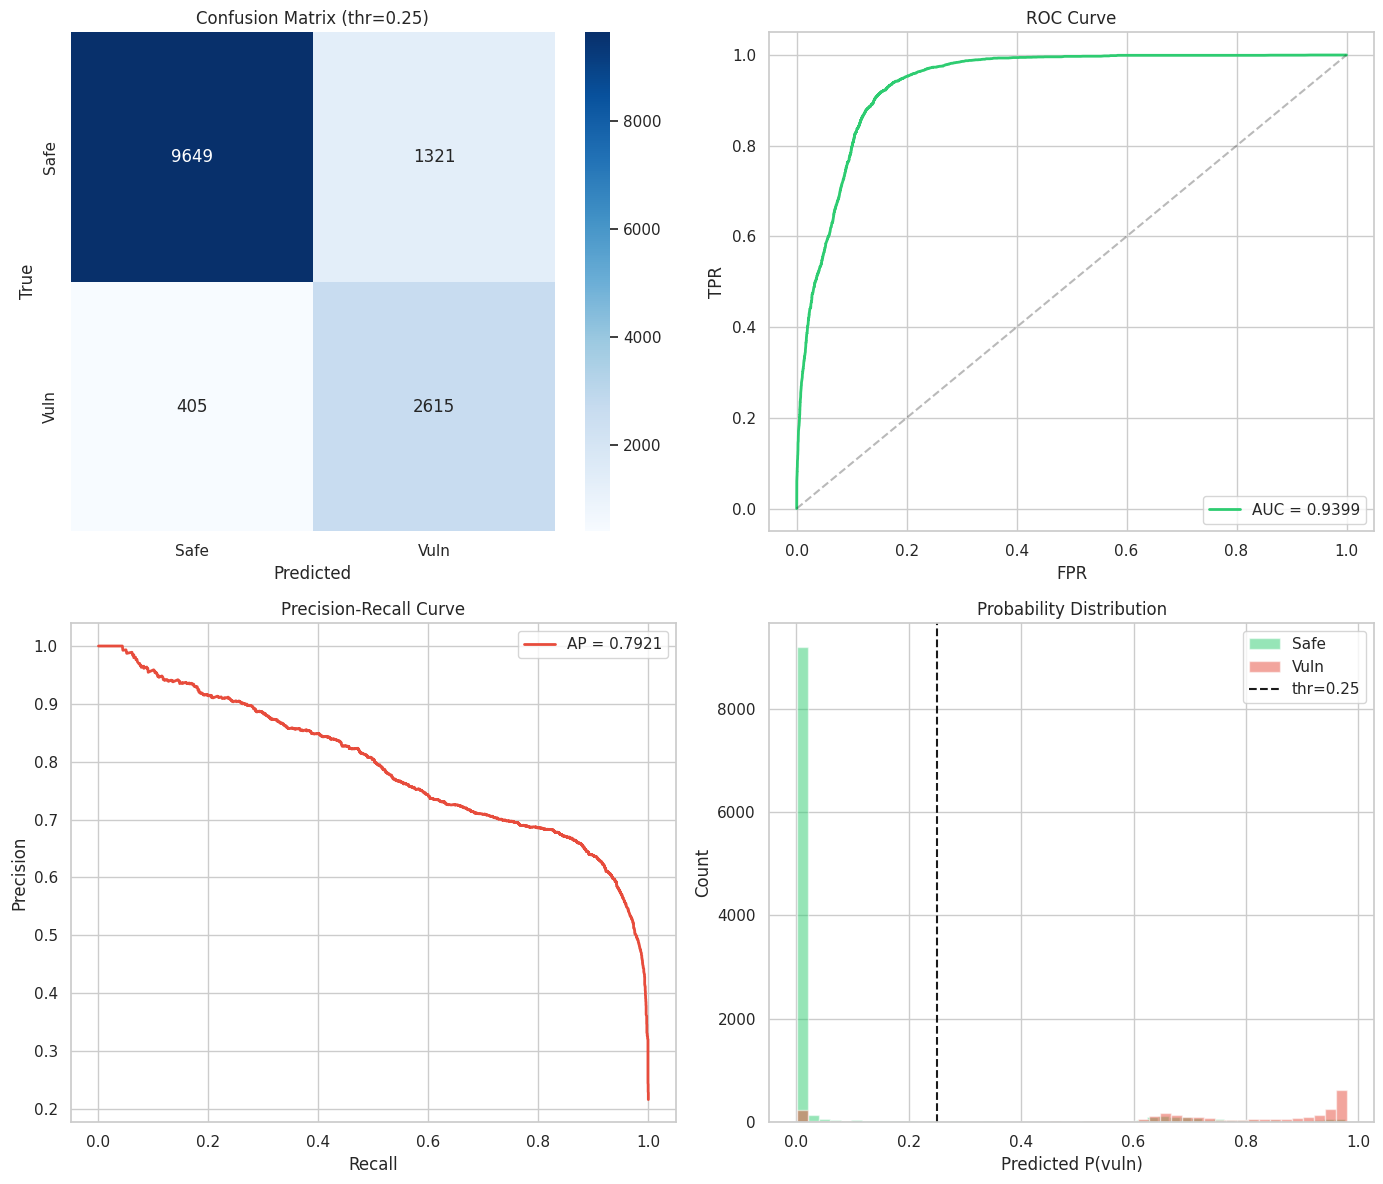

✅ Saved diagnostics to /kaggle/working/diagnostics.png


In [16]:
# Diagnostic plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. Confusion Matrix
cm = confusion_matrix(test_y, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0],
            xticklabels=["Safe", "Vuln"], yticklabels=["Safe", "Vuln"])
axes[0, 0].set_title(f"Confusion Matrix (thr={best_threshold:.2f})")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("True")

# 2. ROC Curve
if len(np.unique(test_y)) > 1:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    auc_val = roc_auc_score(test_y, test_prob)
    axes[0, 1].plot(fpr, tpr, label=f"AUC = {auc_val:.4f}", color="#2ecc71", lw=2)
    axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.3)
    axes[0, 1].set_xlabel("FPR")
    axes[0, 1].set_ylabel("TPR")
    axes[0, 1].set_title("ROC Curve")
    axes[0, 1].legend()

# 3. Precision-Recall Curve
p, r, _ = precision_recall_curve(test_y, test_prob)
ap_val = average_precision_score(test_y, test_prob)
axes[1, 0].plot(r, p, label=f"AP = {ap_val:.4f}", color="#e74c3c", lw=2)
axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].set_title("Precision-Recall Curve")
axes[1, 0].legend()

# 4. Probability distribution
axes[1, 1].hist(test_prob[test_y == 0], bins=50, alpha=0.5, label="Safe", color="#2ecc71")
axes[1, 1].hist(test_prob[test_y == 1], bins=50, alpha=0.5, label="Vuln", color="#e74c3c")
axes[1, 1].axvline(best_threshold, color="k", linestyle="--", label=f"thr={best_threshold:.2f}")
axes[1, 1].set_xlabel("Predicted P(vuln)")
axes[1, 1].set_ylabel("Count")
axes[1, 1].set_title("Probability Distribution")
axes[1, 1].legend()
plt.tight_layout()
SAVE_DIR = Path("/kaggle/working") if IS_KAGGLE else CKPT_DIR
plt.savefig(SAVE_DIR / "diagnostics.png", dpi=120)
plt.show()
print(f"\u2705 Saved diagnostics to {SAVE_DIR}/diagnostics.png")

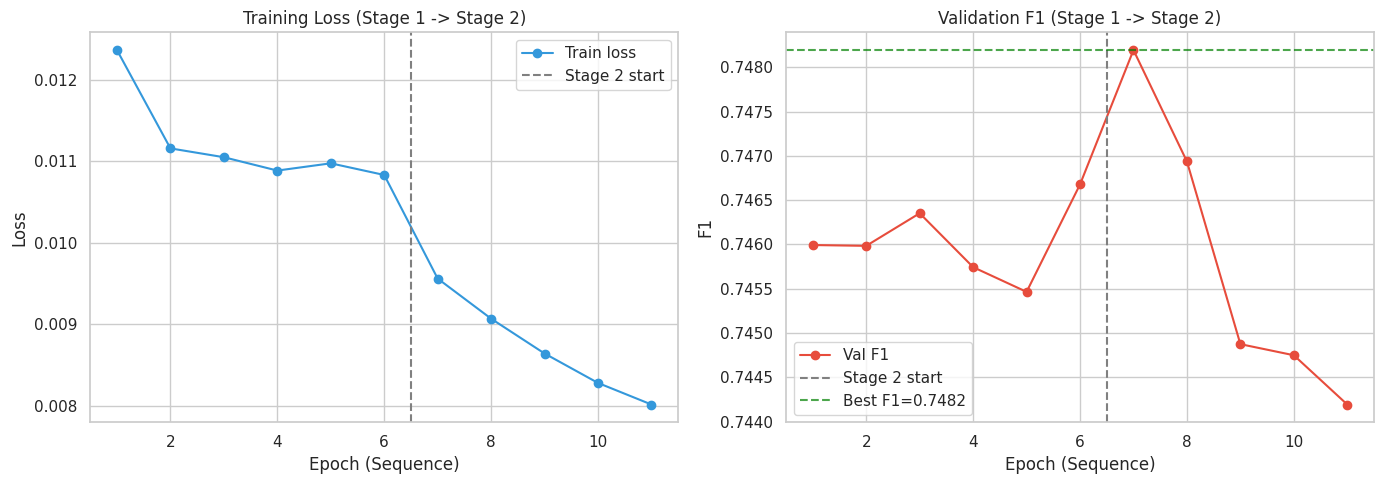

In [17]:
# Training curves (Stage 1 + Stage 2 combined)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
train_losses = [h["train_loss"] for h in history]
val_f1s = [h["val_f1"] for h in history]

axes[0].plot(range(1, len(history) + 1), train_losses, "o-", label="Train loss", color="#3498db")
if len(history_stage1) > 0 and len(history_stage2) > 0:
    axes[0].axvline(len(history_stage1) + 0.5, color="gray", linestyle="--", label="Stage 2 start")
axes[0].set_xlabel("Epoch (Sequence)"); axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss (Stage 1 -> Stage 2)"); axes[0].legend()

axes[1].plot(range(1, len(history) + 1), val_f1s, "o-", label="Val F1", color="#e74c3c")
if len(history_stage1) > 0 and len(history_stage2) > 0:
    axes[1].axvline(len(history_stage1) + 0.5, color="gray", linestyle="--", label="Stage 2 start")
axes[1].axhline(best_f1, color="green", linestyle="--", alpha=0.7, label=f"Best F1={best_f1:.4f}")
axes[1].set_xlabel("Epoch (Sequence)"); axes[1].set_ylabel("F1")
axes[1].set_title("Validation F1 (Stage 1 -> Stage 2)"); axes[1].legend()

plt.tight_layout()
plt.savefig(CKPT_DIR / "training_curves.png", dpi=120)
plt.show()

## 11. Save summary

In [18]:
summary_path = CKPT_DIR / "summary.json"
summary_path.write_text(json.dumps({
    "mode": MODE,
    "best_f1": best_f1,
    "best_threshold": best_threshold,
    "test_metrics": test_metrics.to_dict(),
    "history": history,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\n✅ Saved summary to {summary_path}")
print("\nTrên Kaggle nhớ Save Version / Download checkpoint trước khi hết session.")
print("Done!")


✅ Saved summary to /kaggle/working/models/checkpoints/fusion/summary.json

Trên Kaggle nhớ Save Version / Download checkpoint trước khi hết session.
Done!


In [19]:
# Tạo dataframe chứa kết quả dự đoán trên tập test
import pandas as pd

test_results = pd.DataFrame({
    'sample_id': [s["sample_id"] for s in test_loader.dataset],
    'true_label': test_y,
    'prediction': test_pred,
    'probability': test_prob
})

csv_path = CKPT_DIR / "test_predictions.csv"
test_results.to_csv(csv_path, index=False)
print(f"✅ Đã lưu kết quả dự đoán chi tiết tại: {csv_path}")

✅ Đã lưu kết quả dự đoán chi tiết tại: /kaggle/working/models/checkpoints/fusion/test_predictions.csv


In [20]:
# (Tùy chọn) Nén và tải kết quả xuống
if IS_KAGGLE:
    import shutil
    from IPython.display import FileLink, display

    output_filename = '/kaggle/working/fusion_results'
    shutil.make_archive(
        base_name=output_filename,
        format='zip',
        # root_dir='/kaggle/working',
        root_dir=str(CKPT_DIR.parent.parent),
        base_dir='checkpoints',
    )
    display(FileLink(output_filename + '.zip'))

/kaggle/working/fusion_results.zip